# BiNVaST annotation of the 10x Xenium Prime ovarian-cancer sketch

This notebook reproduces the data setup in the 10x Genomics
[Xenium cell-type annotation guide](https://www.10xgenomics.com/analysis-guides/xenium-cell-type-annotation):
the Xenium Prime FFPE human ovarian-cancer query, the matched 17k Flex
scRNA-seq reference and its supplied cell annotations, and a 100,000-cell
Seurat `LeverageScore` sketch. It then selects 2,000 shared variable
genes, generates query-matched synthetic cells, trains BiNVaST, predicts
query labels, and draws the spatial annotation map.

The executed result below uses a 50-epoch checkpoint on all 100,000 target
and synthetic cells. For a longer scientific analysis, change
`SNAPSHOT_EPOCHS` to (for example) `(50, 100, 150, 200)` and train on an
appropriate GPU. Predictions still require biological validation before
they are interpreted or reported.

Only the four individual files needed for this workflow are downloaded;
the 26.7 GB full Xenium output bundle is not required.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import sys
import urllib.request

import binvast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXAMPLE_DIR = Path.cwd().resolve()
if EXAMPLE_DIR.name != "xenium_10x_guide":
    candidate = EXAMPLE_DIR / "examples" / "xenium_10x_guide"
    if candidate.is_dir():
        EXAMPLE_DIR = candidate
    else:
        raise RuntimeError("Run this notebook from its examples/xenium_10x_guide directory")

REPO_ROOT = EXAMPLE_DIR.parents[1]
RAW_DIR = EXAMPLE_DIR / "data" / "raw"
PREPARED_DIR = EXAMPLE_DIR / "data" / "preprocessed"
SYNTHETIC_DIR = EXAMPLE_DIR / "data" / "synthetic"
RESULTS_DIR = EXAMPLE_DIR / "results"
for directory in (RAW_DIR, PREPARED_DIR, SYNTHETIC_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SNAPSHOT_EPOCHS = (50,)  # Use (50, 100, 150, 200) for more snapshots.
BATCH_SIZE = 8192       # Lower this value if accelerator memory is limited.
SEED = 259

print(f"Python: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"BiNVaST: {binvast.__version__}")
print(f"Repository: {REPO_ROOT}")

Python: 3.9.6
Platform: macOS-26.6.2-arm64-arm-64bit
BiNVaST: 0.1.0
Repository: /Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2


## 1. Download the official 10x data

The Xenium expression matrix and cell-coordinate table come from the
[Xenium Prime FFPE human ovarian-cancer dataset](https://www.10xgenomics.com/datasets/xenium-prime-ffpe-human-ovarian-cancer).
The reference matrix and author-supplied labels come from the matched
[17k human ovarian-cancer scFFPE dataset](https://www.10xgenomics.com/datasets/17k-human-ovarian-cancer-scFFPE).

In [2]:
DOWNLOADS = {
    "Xenium_Prime_Ovarian_Cancer_FFPE_XRrun_cell_feature_matrix.h5": {
        "url": "https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/3.0.0/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun_cell_feature_matrix.h5",
        "sha256": "c96ca28301759b71ad1e41d2cc3f6f3521739bb247ab9265ea7940cf6bb3377e",
    },
    "cells.csv.gz": {
        "url": "https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/3.0.0/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun_cells.csv.gz",
        "sha256": "88a568a7c93aa0fd9bd01d7cf11020cff4767cc3fa14fc6991ed0737f64a3b6d",
    },
    "17k_Ovarian_Cancer_scFFPE_count_filtered_feature_bc_matrix.h5": {
        "url": "https://cf.10xgenomics.com/samples/cell-exp/8.0.1/17k_Ovarian_Cancer_scFFPE/17k_Ovarian_Cancer_scFFPE_count_filtered_feature_bc_matrix.h5",
        "sha256": "1afe0a9c33872564cb546d97d2d887933631571d0a9120adf733ec278c5540e5",
    },
    "FLEX_Ovarian_Barcode_Cluster_Annotation.csv": {
        "url": "https://cf.10xgenomics.com/supp/cell-exp/FLEX_Ovarian_Barcode_Cluster_Annotation.csv",
        "sha256": "a2c1800d829a4a0991c42be6d24b68d53a817fb955926e850dd93cac277523bd",
    },
}

def sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

for filename, metadata in DOWNLOADS.items():
    destination = RAW_DIR / filename
    if not destination.exists():
        print(f"Downloading {filename} ...")
        temporary = destination.with_suffix(destination.suffix + ".part")
        urllib.request.urlretrieve(metadata["url"], temporary)
        temporary.replace(destination)
    observed = sha256(destination)
    if observed != metadata["sha256"]:
        raise RuntimeError(f"Checksum mismatch for {filename}: {observed}")
    print(f"OK  {filename}: {destination.stat().st_size / 1e6:.1f} MB")

OK  Xenium_Prime_Ovarian_Cancer_FFPE_XRrun_cell_feature_matrix.h5: 108.6 MB
OK  cells.csv.gz: 24.9 MB
OK  17k_Ovarian_Cancer_scFFPE_count_filtered_feature_bc_matrix.h5: 30.0 MB
OK  FLEX_Ovarian_Barcode_Cluster_Annotation.csv: 0.8 MB


## 2. Reproduce the 100K-cell sketch and prepare BiNVaST inputs in R

The companion R script follows the 10x guide's target workflow:
`NormalizeData`, `FindVariableFeatures`, and `SketchData` with
`ncells = 100000`, `method = "LeverageScore"`, and seed 123. It applies
the guide's reference QC thresholds, identifies the 4,912 shared genes,
selects 2,000 query-variable shared genes with Seurat VST, and exports
aligned log1p(CP10K) matrices plus spatial coordinates and labels.

In [3]:
preparation_summary = PREPARED_DIR / "preparation_summary.csv"
if not preparation_summary.exists():
    command = [
        "Rscript",
        str(EXAMPLE_DIR / "prepare_10x_guide_data.R"),
        str(RAW_DIR),
        str(PREPARED_DIR),
        str(REPO_ROOT),
    ]
    subprocess.run(command, check=True)
else:
    print("Prepared inputs already exist; reusing them.")

preparation = pd.read_csv(preparation_summary)
display(preparation)

Prepared inputs already exist; reusing them.


,metric,value
0,full_xenium_cells,406611
1,sketch_cells,100000
2,xenium_genes,5101
3,reference_cells_before_qc,17553
4,reference_cells_after_qc,17050
5,reference_labels,16
6,shared_genes,4912
7,selected_genes,2000
8,sketch_method,LeverageScore
9,sketch_seed,123


In [4]:
reference_counts = pd.read_csv(PREPARED_DIR / "reference_label_counts.csv")
selected_genes = pd.read_csv(PREPARED_DIR / "top2000_gene_names.csv")
print(f"Selected genes: {len(selected_genes):,}")
print(f"Reference cell types: {len(reference_counts):,}")
display(reference_counts)

Selected genes: 2,000
Reference cell types: 16


,label,cells
0,Macrophages,2327
1,Tumor Cells,2255
2,Tumor Associated Fibroblasts,2251
3,Proliferative Tumor Cells,1950
4,Stromal Associated Fibroblasts,1375
5,Endothelial Cells,1353
6,VEGFA+ Tumor Cells,1325
7,Smooth Muscle Cells,959
8,Pericytes,881
9,T & NK Cells,812


## 3. Generate query-matched synthetic training cells

`generate_synthetic_data` is part of the installable `binvast` package.
It globally aligns the matched reference to the query, works in PCA space,
assigns cell types using nearest-reference distances and a Gaussian kernel,
and applies dropout-only zero alignment. The output has one synthetic
training cell for every query sketch cell.

In [5]:
from binvast import generate_synthetic_data

synthetic_files = [
    SYNTHETIC_DIR / "synthetic_expression.csv",
    SYNTHETIC_DIR / "synthetic_labels.csv",
    SYNTHETIC_DIR / "synthetic_spatial_coords.csv",
    SYNTHETIC_DIR / "synthetic_cell_type_counts.csv",
]
if not all(path.exists() for path in synthetic_files):
    synthetic_result = generate_synthetic_data(
        input_data_dir=PREPARED_DIR,
        output_dir=SYNTHETIC_DIR,
        pca_base="reference",
        n_pcs=50,
        tau=1.0,
        seed=SEED,
        csv_chunk_size=2000,
        assignment_batch_size=10000,
    )
    print(json.dumps(synthetic_result["verification"], indent=2))
else:
    print("Synthetic inputs already exist; reusing them.")

synthetic_counts = pd.read_csv(SYNTHETIC_DIR / "synthetic_cell_type_counts.csv")
print(f"Synthetic cells: {synthetic_counts.iloc[:, -1].sum():,.0f}")
display(synthetic_counts)

Synthetic inputs already exist; reusing them.
Synthetic cells: 100


,label,N,percentage
0,Ciliated Epithelial Cells,890,0.890
1,Endothelial Cells,6395,6.395
2,Fallopian Tube Epithelium,1510,1.510
3,Granulosa Cells,1029,1.029
4,Inflammatory Tumor Cells,531,0.531
5,"MT-High, Jun+/Fos+ Tumor Cells",4513,4.513
6,Macrophages,10402,10.402
7,Malignant Cells Lining Cyst,573,0.573
8,Pericytes,5685,5.685
9,Proliferative Tumor Cells,13191,13.191


## 4. Train BiNVaST and predict the Xenium sketch labels

The executed demonstration uses 50 epochs and a large CPU batch.
BiNVaST trains its expression and spatial-graph variational branches with
an internal 80/20 synthetic split, saves a checkpoint, and predicts a
label and class probabilities for every real query cell. Add later
epochs to `SNAPSHOT_EPOCHS` near the top for a longer run.

In [6]:
from binvast import train_and_predict

final_epoch = max(SNAPSHOT_EPOCHS)
snapshot_dir = RESULTS_DIR / f"epochs_{final_epoch:03d}_batch_{BATCH_SIZE:05d}"
prediction_file = snapshot_dir / "target_predicted_labels.csv"

if not prediction_file.exists():
    workflow_result = train_and_predict(
        project_dir=REPO_ROOT,
        target_data_dir=PREPARED_DIR,
        synthetic_data_dir=SYNTHETIC_DIR,
        output_dir=RESULTS_DIR,
        snapshot_epochs=SNAPSHOT_EPOCHS,
        batch_size=BATCH_SIZE,
        graph_k=30,
        expr_latent_dim=4,
        graph_latent_dim=4,
        seed=SEED,
    )
    print(json.dumps(workflow_result["manifest"], indent=2))
else:
    print(f"Completed predictions already exist; reusing {prediction_file}")

run_manifest = json.loads((snapshot_dir / "run_manifest.json").read_text())
print(json.dumps(run_manifest, indent=2))
validation_history = pd.read_csv(snapshot_dir / "training_history.csv")
validation_history = validation_history.dropna(subset=["val_accuracy"])
print("Internal validation checkpoints:")
display(validation_history[["epoch", "val_accuracy", "val_macro_f1", "val_selection_score"]])

Completed predictions already exist; reusing /Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2/examples/xenium_10x_guide/results/epochs_050_batch_08192/target_predicted_labels.csv
{
  "dataset": "high_resolution_spatial_transcriptomics",
  "training_mode": "continuous_epoch_snapshots",
  "project_root": "/Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2",
  "target_dir": "/Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2/examples/xenium_10x_guide/data/preprocessed",
  "synthetic_dir": "/Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2/examples/xenium_10x_guide/data/synthetic",
  "snapshot_epoch": 50,
  "continuous_training_max_epoch": 50,
  "batch_size": 8192,
  "seed": 259,
  "graph_k_neighbors": 30,
  "expr_latent_dim": 4,
  "graph_latent_dim": 4,
  "training_synthetic_cells": 100000,
  "target_cells": 100000,
  "checkpoint": "/Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2/examples/xenium_10x_guide/results/epochs_050_batch_08192/binvast_best_model.pt",
  "synthetic_full_

,epoch,val_accuracy,val_macro_f1,val_selection_score
0,1,0.14495,0.032019,0.111071
9,10,0.37110,0.136062,0.300589
19,20,0.61510,0.345116,0.534105
29,30,0.67185,0.409007,0.592997
39,40,0.70520,0.451064,0.628959
49,50,0.70255,0.462559,0.630553


In [7]:
predictions = pd.read_csv(prediction_file)
label_counts = (
    predictions["predicted_label"]
    .value_counts()
    .rename_axis("predicted_label")
    .reset_index(name="cells")
)
label_counts["proportion"] = label_counts["cells"] / len(predictions)
print(f"Predicted cells: {len(predictions):,}")
print(f"Predicted labels represented: {predictions['predicted_label'].nunique()}")
print("Prediction-confidence summary:")
display(predictions["prediction_confidence"].describe().to_frame().T)
display(label_counts)

Predicted cells: 100,000
Predicted labels represented: 13
Prediction-confidence summary:


,count,mean,std,min,25%,50%,75%,max
prediction_confidence,100000.0,0.710095,0.216882,0.198818,0.520102,0.731832,0.913217,0.999909


,predicted_label,cells,proportion
0,Tumor Cells,27170,0.27170
1,Tumor Associated Fibroblasts,14349,0.14349
2,Proliferative Tumor Cells,13430,0.13430
3,Macrophages,11500,0.11500
4,Stromal Associated Fibroblasts,9048,0.09048
5,Smooth Muscle Cells,8685,0.08685
6,T & NK Cells,4992,0.04992
7,Endothelial Cells,4385,0.04385
8,Pericytes,2310,0.02310
9,"MT-High, Jun+/Fos+ Tumor Cells",2270,0.02270


## 5. Spatial map of the BiNVaST predictions

Each point is one cell from the same 100,000-cell Xenium sketch used as
the BiNVaST target. The y-axis is inverted to display the tissue in image
coordinates.

Saved: /Users/jzhang55/Downloads/BiNVaST/BiNVaST_GitHub_v2/examples/xenium_10x_guide/results/binvast_predicted_labels_spatial.png


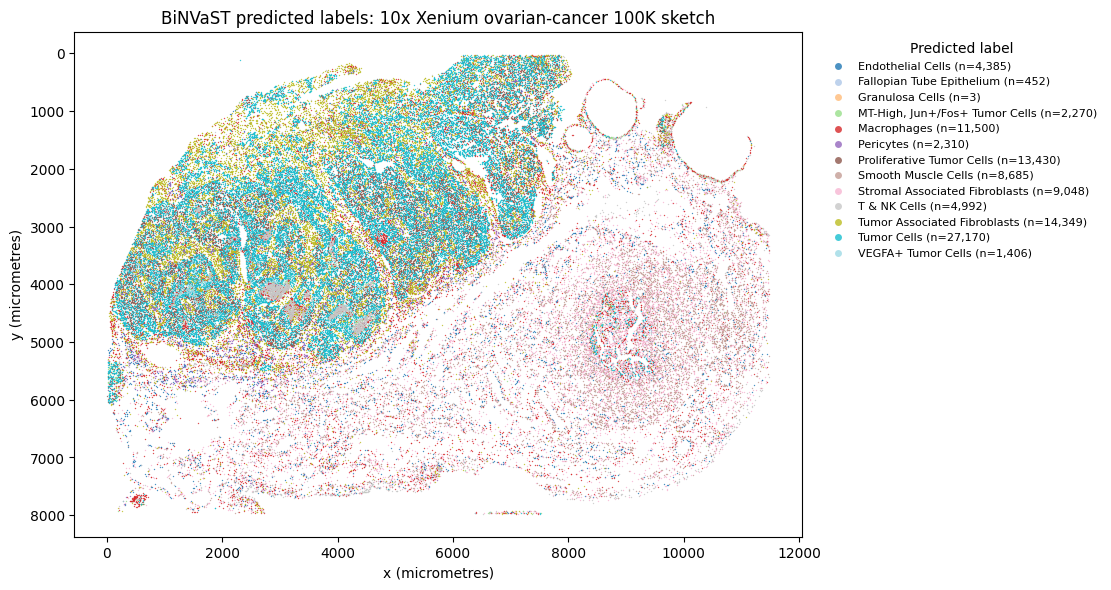

In [8]:
labels = sorted(predictions["predicted_label"].unique())
palette = plt.get_cmap("tab20", len(labels))
color_lookup = {label: palette(index) for index, label in enumerate(labels)}

fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
for label in labels:
    subset = predictions.loc[predictions["predicted_label"] == label]
    ax.scatter(
        subset["x"], subset["y"], s=1.0, alpha=0.80,
        color=color_lookup[label], label=f"{label} (n={len(subset):,})",
        linewidths=0, rasterized=True,
    )
ax.set_title("BiNVaST predicted labels: 10x Xenium ovarian-cancer 100K sketch")
ax.set_xlabel("x (micrometres)")
ax.set_ylabel("y (micrometres)")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.legend(
    title="Predicted label", bbox_to_anchor=(1.02, 1), loc="upper left",
    markerscale=5, frameon=False, fontsize=8,
)
output_figure = RESULTS_DIR / "binvast_predicted_labels_spatial.png"
fig.savefig(output_figure, dpi=300, bbox_inches="tight")
print(f"Saved: {output_figure}")
plt.show()

## Interpretation and reproducibility note

This executed notebook verifies the complete route from the official 10x
files through a 50-epoch checkpoint to 100,000 spatial predictions. A
production analysis should consider multiple later epoch snapshots,
select a converged checkpoint using the internal validation metrics, and
evaluate marker-gene and spatial plausibility before reporting cell types.